## China_industry_ecology_visualization

1. Загрузка данных по провинциям Китая, сформированных в DBeaver
2. Доходы населения по провинциям Китая
3. Визуализация данных (промышленность Китая, экологические показатели, уровень доходов) по провинциям Китая 2011-2024
4. Визуализация заболеваемости астмой и онкологическими заболеваниями дыхательной системы в Китае и странах Азии 2011-2023
5. Визуализация рождаемости и ожидаемой продолжительности жизни в Китае по провинциям 2011-2023
6. Выводы


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import PowerNorm
import geopandas as gpd

## 1. Загрузка данных по провинциям Китая, сформированных в DBeaver

In [2]:
df = pd.read_csv('../data/processed/china_analysis_202611160928.csv')

In [3]:
regions = sorted(df['region'].unique())

## 2. Доходы населения по провинциям Китая

In [4]:
income = df[['region','year','cpi_index']].copy()
income

,region,year,cpi_index
0,Чжэцзян,2024,100.3
1,Чжэцзян,2023,100.3
2,Чжэцзян,2022,102.2
3,Чжэцзян,2021,101.5
4,Чжэцзян,2020,102.3
...,...,...,...
429,Юньнань,2015,101.9
430,Юньнань,2014,102.4
431,Юньнань,2013,103.1
432,Юньнань,2012,102.7


## Расчет накопительного коэффициента инфляции

In [5]:
income['cpi_factor'] = income['cpi_index'] / 100
income.loc[income['year'] == 2011, 'cpi_factor'] = 1
income = income.sort_values(['region', 'year'])
income['cpi_cumulative'] = income.groupby('region')['cpi_factor'].cumprod()

In [6]:
income['disposable_income_urban_output'] = df['disposable_income_urban_output']
income['disposable_income_rural_output'] = df['disposable_income_rural_output']
income['disposable_income_total_output'] = df['disposable_income_total_output']

income['income_urban_real'] = income['disposable_income_urban_output'] / income['cpi_cumulative']
income['income_rural_real'] = income['disposable_income_rural_output'] / income['cpi_cumulative']
income['income_total_real'] = income['disposable_income_total_output'] / income['cpi_cumulative']

In [7]:
income[['region','year','disposable_income_urban_output',
        'disposable_income_rural_output','disposable_income_total_output','income_urban_real',
        'income_rural_real','income_total_real']].round(2).head(5)

,region,year,disposable_income_urban_output,disposable_income_rural_output,disposable_income_total_output,income_urban_real,income_rural_real,income_total_real
97,Аньхой,2011,18345,6811,11873,18345.00,6811.00,11873.00
96,Аньхой,2012,20729,7826,13593,20262.95,7650.05,13287.39
95,Аньхой,2013,22789,8850,15154,21754.53,8448.27,14466.11
94,Аньхой,2014,24839,9916,16796,23338.06,9316.81,15781.07
93,Аньхой,2015,26936,10821,18363,24983.56,10036.65,17031.97


In [8]:
# jiangsu.columns

## 3. Визуализация данных (промышленность Китая, экологические показатели, уровень доходов) по провинциям Китая 2011-2024

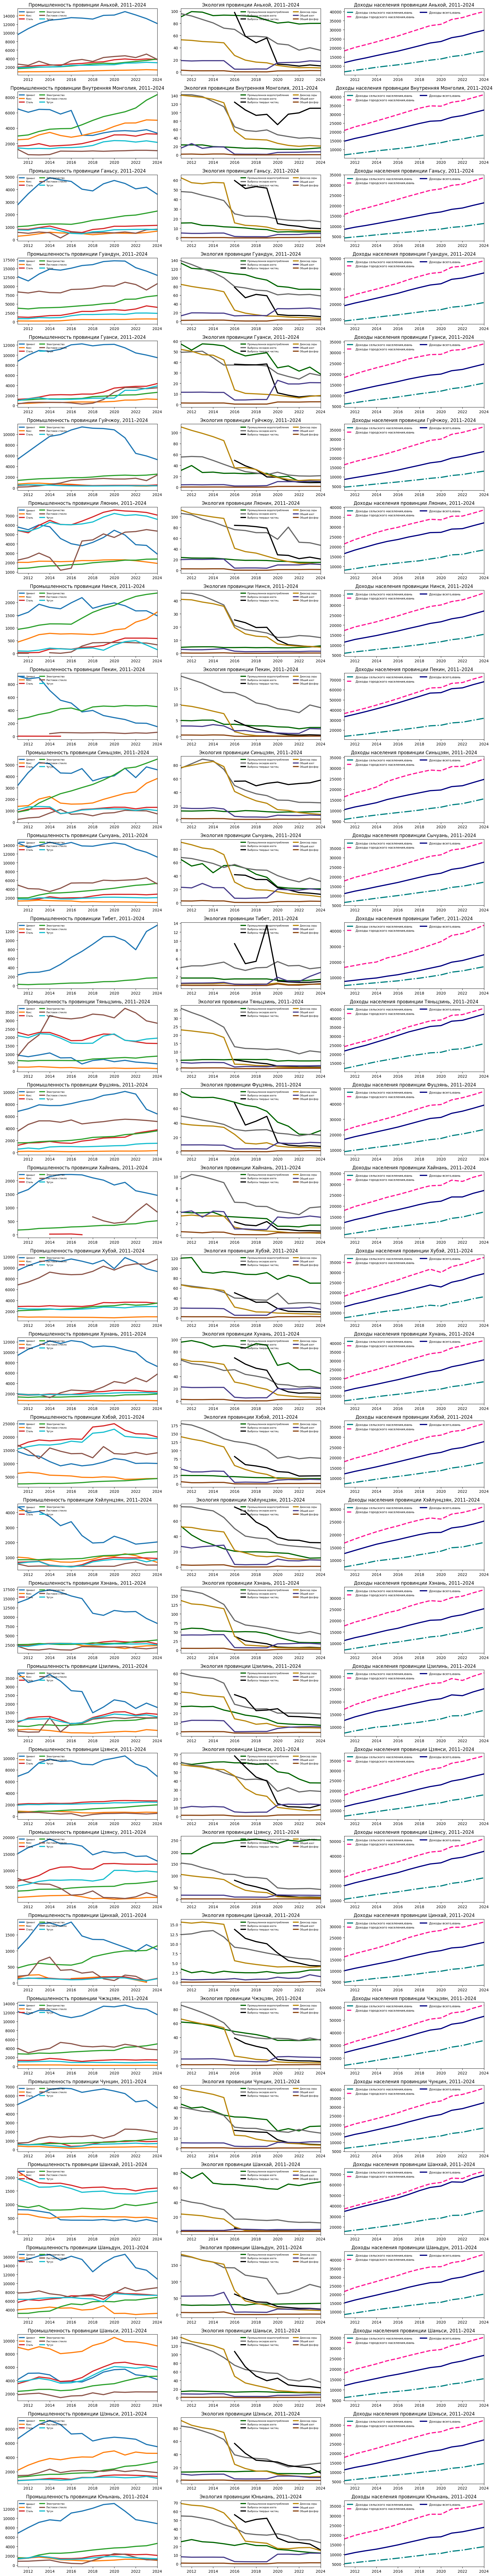

In [9]:
fig, ax = plt.subplots(31,3,figsize=(18, 100))

for i, region in enumerate(regions):
    province = df[df['region'] == region].sort_values('year')
    ax[i,0].plot(province['year'],province['cement_output'],color='tab:blue',linewidth=3,label='Цемент')
    ax[i,0].plot(province['year'],province['coke_output'],color='tab:orange',linewidth=3,label='Кокс')
    ax[i,0].plot(province['year'],province['crude_steel_output'],color='tab:red',linewidth=3,label='Сталь')
    ax[i,0].plot(province['year'],province['electricity_total_output'],color='tab:green',linewidth=3,label='Электричество')
    ax[i,0].plot(province['year'],province['flat_glass_output'],color='tab:brown',linewidth=3,label='Листовое стекло')
    ax[i,0].plot(province['year'],province['pig_iron_output'],color='tab:cyan',linewidth=3,label='Чугун')
    
    ax[i,0].set_xlim(2011,2024)
    ax[i,0].set_title(f'Промышленность провинции {region}, 2011–2024')
    ax[i,0].legend(loc='upper left',fontsize=6,frameon=False,ncol=2)

    ## Экология Китая по провинциям

for i, region in enumerate(regions):
    province = df[df['region'] == region].sort_values('year')
    ax[i,1].plot(province['year'],province['industrial_water_use_output'],color='darkgreen',linewidth=3,label='Промышленное водопотребление')
    ax[i,1].plot(province['year'],province['nox_emissions_output'],color='dimgray',linewidth=3,label='Выбросы оксидов азота')
    ax[i,1].plot(province['year'],province['particulate_emissions_output'],color='black',linewidth=3,label='Выбросы твердых частиц')
    ax[i,1].plot(province['year'],province['so2_emissions_output'],color='darkgoldenrod',linewidth=3,label='Диоксид серы')
    ax[i,1].plot(province['year'],province['total_nitrogen_output'],color='darkslateblue',linewidth=3,label='Общий азот')
    ax[i,1].plot(province['year'],province['total_phosphorus_output'],color='saddlebrown',linewidth=3,label='Общий фосфор')
    
    ax[i,1].set_xlim(2011,2024)
    ax[i,1].set_title(f'Экология провинции {region}, 2011–2024')
    ax[i,1].legend(loc='upper right',fontsize=6,frameon=False,ncol=2)

## Доходы населения Китая по провинциям

for i, region in enumerate(regions):
    province = income[income['region'] == region].sort_values('year')
    ax[i,2].plot(province['year'],province['income_rural_real'],color='teal', linestyle='-.',linewidth=3,label='Доходы сельского населения,юань')
    ax[i,2].plot(province['year'],province['income_urban_real'],color='deeppink', linestyle='--',linewidth=3,label='Доходы городского населения,юань')
    ax[i,2].plot(province['year'],province['income_total_real'],color='navy', linestyle='-',linewidth=3,label='Доходы всего,юань')
    
    ax[i,2].set_xlim(2011,2024)
    ax[i,2].set_title(f'Доходы населения провинции {region}, 2011–2024')
    ax[i,2].legend(loc='upper left',fontsize=8,frameon=False,ncol=2)


plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig('../figures/industry_environment.png', dpi=150, bbox_inches='tight')


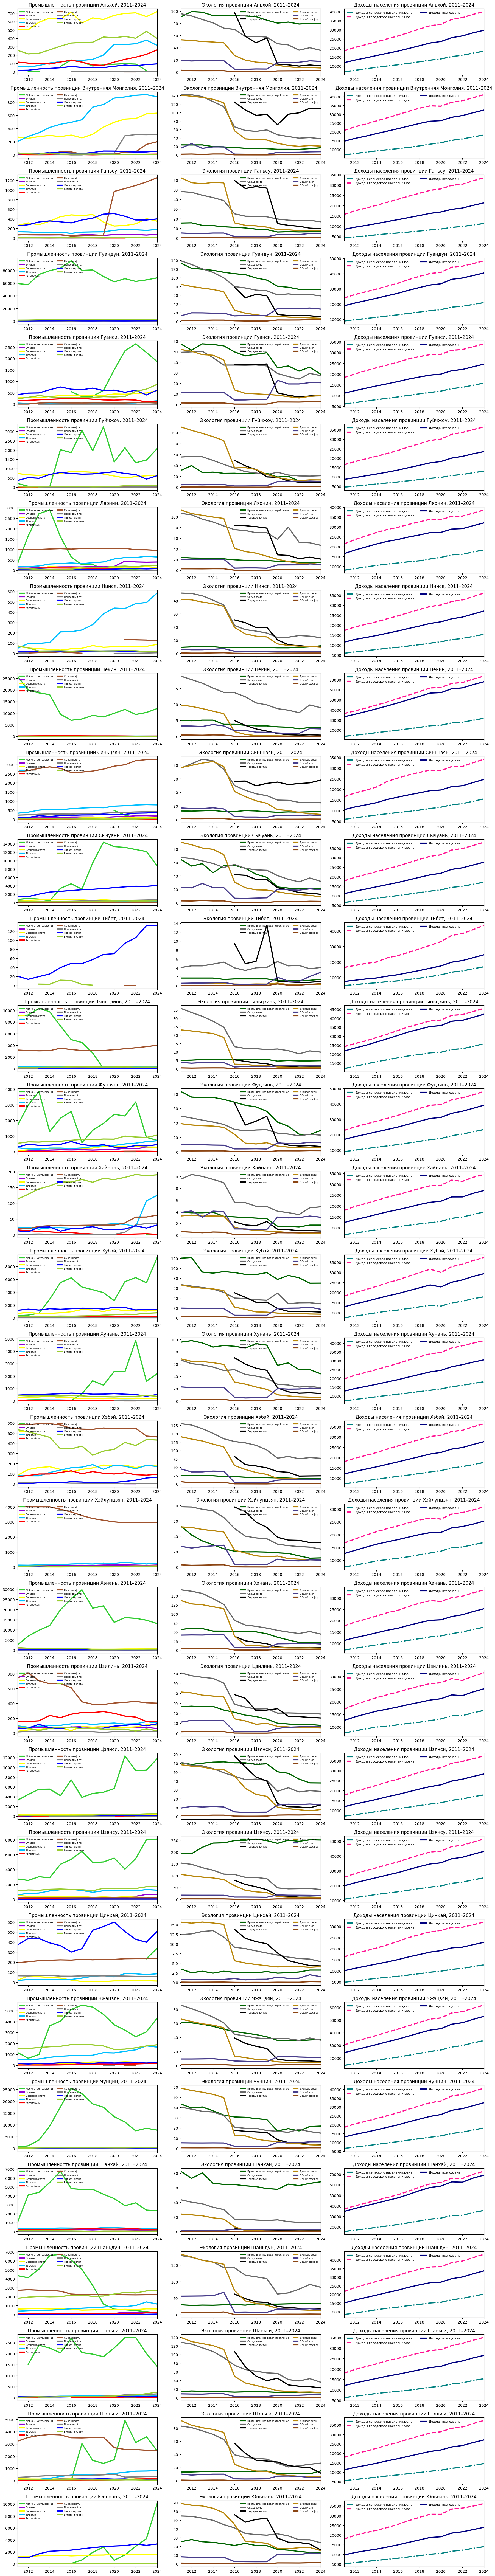

In [10]:
fig, ax = plt.subplots(31,3,figsize=(18, 100))
## Промышленность Китая по провинциям

for i, region in enumerate(regions):
    province = df[df['region'] == region].sort_values('year')
    ax[i,0].plot(province['year'], province['mobile_phones_output'], color='limegreen', linewidth=3, label='Мобильные телефоны')
    ax[i,0].plot(province['year'], province['ethylene_output'], color='darkviolet', linewidth=3, label='Этилен')
    ax[i,0].plot(province['year'], province['sulfuric_acid_output'], color='yellow', linewidth=3, label='Серная кислота')
    ax[i,0].plot(province['year'], province['primary_plastics_output'], color='deepskyblue', linewidth=3, label='Пластик')
    ax[i,0].plot(province['year'], province['automobiles_output'], color='red', linewidth=3, label='Автомобили')
    ax[i,0].plot(province['year'], province['crude_oil_output'], color='sienna', linewidth=3, label='Сырая нефть')
    ax[i,0].plot(province['year'], province['natural_gas_output'], color='gray', linewidth=3, label='Природный газ')
    ax[i,0].plot(province['year'], province['hydropower_output'], color='blue', linewidth=3, label='Гидроэнергия')
    ax[i,0].plot(province['year'], province['paper_board_output'], color='yellowgreen', linewidth=3, label='Бумага и картон')
    
    ax[i,0].set_xlim(2011,2024)
    ax[i,0].set_title(f'Промышленность провинции {region}, 2011–2024')
    ax[i,0].legend(loc='upper left',fontsize=6,frameon=False,ncol=2)

    ## Экология Китая по провинциям

for i, region in enumerate(regions):
    province = df[df['region'] == region].sort_values('year')
    ax[i,1].plot(province['year'],province['industrial_water_use_output'],color='darkgreen',linewidth=3,label='Промышленное водопотребление')
    ax[i,1].plot(province['year'],province['nox_emissions_output'],color='dimgray',linewidth=3,label='Оксид азота')
    ax[i,1].plot(province['year'],province['particulate_emissions_output'],color='black',linewidth=3,label='Твердые частиц')
    ax[i,1].plot(province['year'],province['so2_emissions_output'],color='darkgoldenrod',linewidth=3,label='Диоксид серы')
    ax[i,1].plot(province['year'],province['total_nitrogen_output'],color='darkslateblue',linewidth=3,label='Общий азот')
    ax[i,1].plot(province['year'],province['total_phosphorus_output'],color='saddlebrown',linewidth=3,label='Общий фосфор')
    
    ax[i,1].set_xlim(2011,2024)
    ax[i,1].set_title(f'Экология провинции {region}, 2011–2024')
    ax[i,1].legend(loc='upper right',fontsize=6,frameon=False,ncol=2)

## Доходы населения Китая по провинциям

for i, region in enumerate(regions):
    province = income[income['region'] == region].sort_values('year')
    ax[i,2].plot(province['year'],province['income_rural_real'],color='teal', linestyle='-.',linewidth=3,label='Доходы сельского населения,юань')
    ax[i,2].plot(province['year'],province['income_urban_real'],color='deeppink', linestyle='--',linewidth=3,label='Доходы городского населения,юань')
    ax[i,2].plot(province['year'],province['income_total_real'],color='navy', linestyle='-',linewidth=3,label='Доходы всего,юань')
    
    ax[i,2].set_xlim(2011,2024)
    ax[i,2].set_title(f'Доходы населения провинции {region}, 2011–2024')
    ax[i,2].legend(loc='upper left',fontsize=8,frameon=False,ncol=2)


plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig('../figures/industry_additional.png', dpi=150, bbox_inches='tight')

## Анализ заболеваемости астмой и онкологическими заболеваниями дыхательной системы в Китае 2011-2023

In [11]:
df_asthma = pd.read_csv('../data/raw/china_asthma_2011_2023.csv')
df_larynx_cancer = pd.read_csv('../data/raw/china_larynx_cancer_2011_2023.csv')
df_lung_cancer = pd.read_csv('../data/raw/china_lung_cancer_2011_2023.csv')
df_diseases_asia = pd.read_csv('../data/raw/asia_diseases_2011_2023.csv')

In [12]:
df_diseases = pd.concat([df_asthma,df_larynx_cancer,df_lung_cancer,df_diseases_asia],ignore_index=True)

In [13]:
df_diseases.columns

Index(['population_group_id', 'population_group_name', 'measure_id',
       'measure_name', 'location_id', 'location_name', 'sex_id', 'sex_name',
       'age_id', 'age_name', 'cause_id', 'cause_name', 'metric_id',
       'metric_name', 'year', 'val', 'upper', 'lower'],
      dtype='str')

In [14]:
df_diseases = df_diseases[['cause_name','year','val','upper','lower','location_name']].sort_values(['cause_name','year'])
df_diseases.head(20)

,cause_name,year,val,upper,lower,location_name
5,Asthma,2011,587.703719,740.203097,469.941747,China
41,Asthma,2011,828.663225,1028.214318,662.504814,Japan
42,Asthma,2011,355.988465,441.873582,287.474116,Mongolia
46,Asthma,2011,591.050237,699.409234,487.832616,Republic of Korea
56,Asthma,2011,619.767595,783.387982,501.191365,India
64,Asthma,2011,907.996543,1108.458177,713.035026,Viet Nam
100,Asthma,2011,669.865867,818.278337,533.361610,Russian Federation
2,Asthma,2012,592.599240,743.833525,472.583892,China
39,Asthma,2012,913.483514,1108.123816,720.427866,Viet Nam
40,Asthma,2012,356.287354,442.644152,287.774680,Mongolia


In [15]:
df_diseases_asthma = df_diseases[df_diseases['cause_name'] == 'Asthma']

df_diseases_larynx_cancer = df_diseases[df_diseases['cause_name'] == 'Larynx cancer']

df_diseases_lung_cancer = df_diseases[df_diseases['cause_name'] == 'Tracheal, bronchus, and lung cancer']

## 4. Визуализация заболеваемости астмой и онкологическими заболеваниями органов дыхания в Китае (2011-2023)

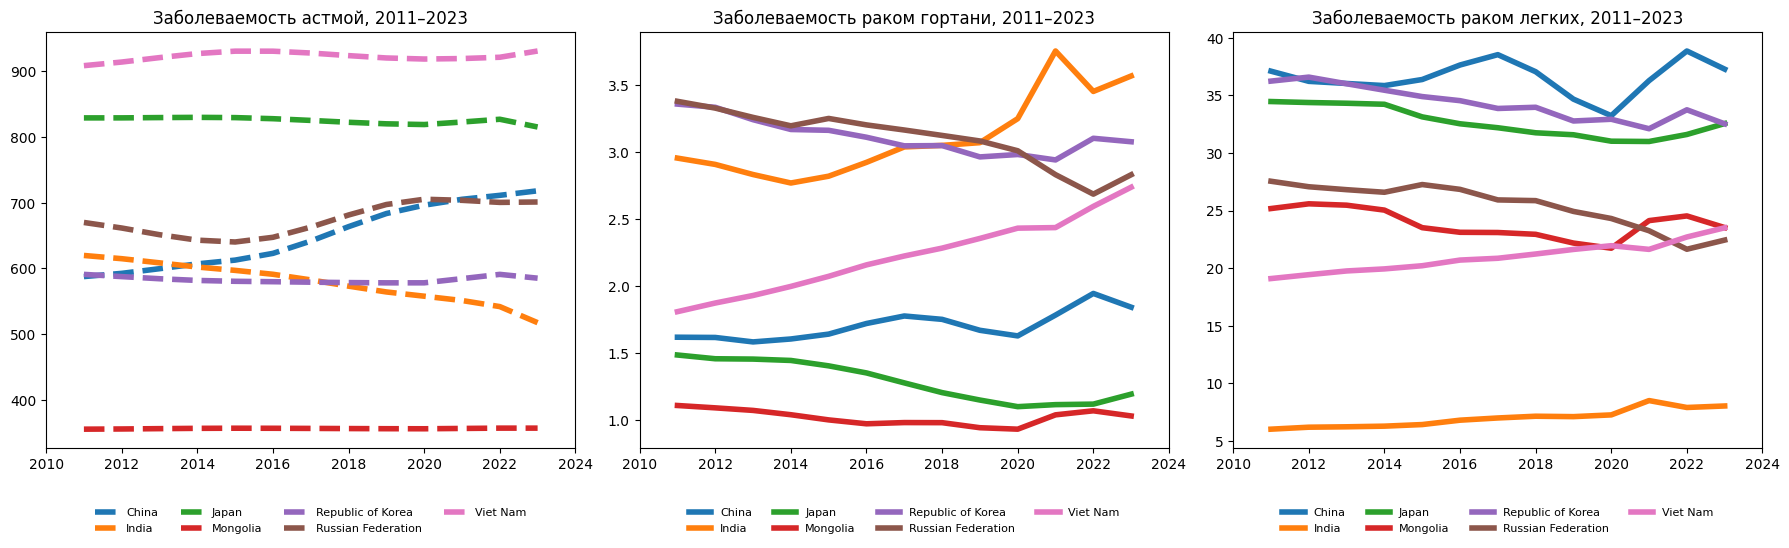

In [16]:
fig, ax = plt.subplots(1,3,figsize=(18, 6))

### Заболеваемость астмой в странах Азии 2011-2023

for country, group in df_diseases_asthma.groupby('location_name'):
    ax[0].plot(group['year'], group['val'], label=country, linewidth=4, linestyle='--')
    ax[0].set_xlim(2010, 2024)
    ax[0].set_title('Заболеваемость астмой, 2011–2023')
    ax[0].legend(fontsize=8, loc='upper center',bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)

### Заболеваемость раком гортани в странах Азии 2011-2023

for country, group in df_diseases_larynx_cancer.groupby('location_name'):
    ax[1].plot(group['year'], group['val'], label=country, linewidth=4, linestyle='-')
    ax[1].set_xlim(2010, 2024)
    ax[1].set_title('Заболеваемость раком гортани, 2011–2023')
    ax[1].legend(fontsize=8, loc='upper center',bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)


## Заболеваемость раком легких в странах Азии 2011-2023
for country, group in df_diseases_lung_cancer.groupby('location_name'):
    ax[2].plot(group['year'], group['val'], label=country, linewidth=4, linestyle='-')
    ax[2].set_xlim(2010, 2024)
    ax[2].set_title('Заболеваемость раком легких, 2011–2023')
    ax[2].legend(fontsize=8, loc='upper center',bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig('../figures/diseases_comparison.png', dpi=150, bbox_inches='tight')

## Ожидаемая продолжительность жизни по провинциям Китая 2011-2023

In [17]:
df_life = pd.read_csv('../data/raw/china_life_expectancy_2011_2023.csv')

In [18]:
df_life.head()

,Country,Continent,ISO_Code,Level,GDLCODE,Region,Year,lifexp
0,China,Asia/Pacific,CHN,Subnat,CHNr112,Anhui,2011,75.72
1,China,Asia/Pacific,CHN,Subnat,CHNr112,Anhui,2012,76.02
2,China,Asia/Pacific,CHN,Subnat,CHNr112,Anhui,2013,76.26
3,China,Asia/Pacific,CHN,Subnat,CHNr112,Anhui,2014,76.52
4,China,Asia/Pacific,CHN,Subnat,CHNr112,Anhui,2015,76.77


In [19]:
df_life_clean = df_life[~df_life['Region'].isin(['Taiwan','Hongkong'])]

## Число рождений на 1000 жителей в Китае по провинциям 2011-2024


In [20]:
df_fertility = pd.read_csv('../data/raw/china_birth_rate_2011_2023.xlsx.csv')

In [21]:
df_fertility.head()

,地区,2025年,2024年,2023年,2022年,2021年,2020年,2019年,2018年,2017年,2016年,2015年,2014年,2013年,2012年,2011年
0,北京市,NaN,6.09,5.63,5.67,6.35,6.99,8.12,8.24,9.06,9.32,7.96,9.75,8.93,9.05,8.29
1,天津市,NaN,4.99,4.47,4.75,5.30,5.99,6.73,6.67,7.65,7.37,5.84,8.19,8.28,8.75,8.58
2,河北省,NaN,5.90,5.54,6.09,7.15,8.16,10.83,11.26,13.20,12.42,11.35,13.18,13.04,12.88,13.02
3,山西省,NaN,6.94,6.13,6.75,7.06,8.26,9.12,9.63,11.06,10.29,9.98,10.92,10.81,10.70,10.47
4,内蒙古自治区\t,NaN,5.52,5.00,5.58,6.26,7.20,8.23,8.35,9.47,9.03,7.72,9.31,8.98,9.17,8.94


In [22]:
df_region = pd.read_csv('../data/raw/region_202611171534.csv')

## Соединение данных о рождаемости с названиями регионов на русском языке

In [23]:
df_fertility_reg = df_fertility.merge(df_region,left_on='地区',right_on='name_china',how='left',validate='one_to_one')

In [24]:
df_fertility_reg.head()

,地区,2025年,2024年,2023年,2022年,2021年,2020年,2019年,2018年,2017年,2016年,2015年,2014年,2013年,2012年,2011年,name_region,name_china
0,北京市,NaN,6.09,5.63,5.67,6.35,6.99,8.12,8.24,9.06,9.32,7.96,9.75,8.93,9.05,8.29,Пекин,北京市
1,天津市,NaN,4.99,4.47,4.75,5.30,5.99,6.73,6.67,7.65,7.37,5.84,8.19,8.28,8.75,8.58,Тяньцзинь,天津市
2,河北省,NaN,5.90,5.54,6.09,7.15,8.16,10.83,11.26,13.20,12.42,11.35,13.18,13.04,12.88,13.02,Хэбэй,河北省
3,山西省,NaN,6.94,6.13,6.75,7.06,8.26,9.12,9.63,11.06,10.29,9.98,10.92,10.81,10.70,10.47,Шаньси,山西省
4,内蒙古自治区\t,NaN,5.52,5.00,5.58,6.26,7.20,8.23,8.35,9.47,9.03,7.72,9.31,8.98,9.17,8.94,Внутренняя Монголия,内蒙古自治区\t


In [25]:
df_fertility_reg['name_region'].unique()

<ArrowStringArray>
[              'Пекин',           'Тяньцзинь',               'Хэбэй',
              'Шаньси', 'Внутренняя Монголия',              'Ляонин',
             'Цзилинь',          'Хэйлунцзян',              'Шанхай',
              'Цзянсу',             'Чжэцзян',              'Аньхой',
             'Фуцзянь',              'Цзянси',             'Шаньдун',
              'Хэнань',               'Хубэй',              'Хунань',
             'Гуандун',              'Гуанси',             'Хайнань',
              'Чунцин',             'Сычуань',             'Гуйчжоу',
             'Юньнань',               'Тибет',              'Шэньси',
              'Ганьсу',              'Цинхай',               'Нинся',
            'Синьцзян']
Length: 31, dtype: str

In [26]:
df_fertility_reg = df_fertility_reg.drop(columns=['地区', 'name_china'])

In [27]:
df_fertility_reg.columns = df_fertility_reg.columns.str.replace('年','')

In [28]:
df_fertility_reg = df_fertility_reg.drop(columns='2025')

## Изменение расположения лет в таблице ( из колонок в строки)

In [29]:
df_fertility_reg = df_fertility_reg.melt(id_vars='name_region')

In [30]:
df_fertility_reg = df_fertility_reg.rename(columns={'variable':'year','value':'birth_rate'})

In [31]:
df_fertility_reg = df_fertility_reg.sort_values(['name_region','year'])

In [32]:
df_fertility_reg['year'] = df_fertility_reg['year'].astype(int)
df_fertility_reg.info()

<class 'pandas.DataFrame'>
Index: 434 entries, 414 to 24
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   name_region  434 non-null    str    
 1   year         434 non-null    int64  
 2   birth_rate   434 non-null    float64
dtypes: float64(1), int64(1), str(1)
memory usage: 19.4 KB


In [33]:
df_life['Region'].unique()

<ArrowStringArray>
[         'Anhui',        'Beijing',      'Chongqing',         'Fujian',
          'Gansu',      'Guangdong',        'Guangxi',        'Guizhou',
         'Hainan',          'Hebei',   'Heilongjiang',          'Henan',
       'Hongkong',          'Hubei',          'Hunan', 'Inner Mongolia',
        'Jiangsu',        'Jiangxi',          'Jilin',       'Liaoning',
        'Ningxia',        'Qinghai',        'Shaanxi',       'Shandong',
       'Shanghai',         'Shanxi',        'Sichuan',         'Taiwan',
        'Tianjin',          'Tibet',       'Xinjiang',         'Yunnan',
       'Zhejiang']
Length: 33, dtype: str

In [34]:
df_region['name_region'].unique()

<ArrowStringArray>
[            'Чжэцзян',              'Хунань',             'Хайнань',
              'Ляонин',             'Гуандун',              'Цзянси',
              'Аньхой',              'Гуанси',             'Цзилинь',
               'Нинся',             'Гуйчжоу',              'Цинхай',
            'Синьцзян',              'Шанхай',           'Тяньцзинь',
               'Хэбэй', 'Внутренняя Монголия',             'Сычуань',
             'Шаньдун',             'Фуцзянь',              'Цзянсу',
              'Шаньси',               'Тибет',               'Хубэй',
               'Пекин',              'Ганьсу',              'Шэньси',
              'Хэнань',              'Чунцин',          'Хэйлунцзян',
             'Юньнань']
Length: 31, dtype: str

In [35]:
region_en_ru = {
    'Anhui':'Аньхой',
     'Gansu':'Ганьсу',
     'Hainan': 'Хайнань',
     'Jiangsu':'Цзянсу',
     'Ningxia':'Нинся',
     'Shanghai':'Шанхай',
     'Tianjin':'Тяньцзинь',
    'Zhejiang': 'Чжэцзян',
    'Beijing':'Пекин',
    'Guangdong':'Гуандун',
    'Hebei':'Хэбэй',
    'Hubei':'Хубэй',
    'Jiangxi':'Цзянси',
    'Qinghai': 'Цинхай',
    'Shanxi':'Шаньси',
    'Tibet':'Тибет',
    'Chongqing': 'Чунцин',
    'Guangxi':'Гуанси',
    'Heilongjiang':'Хэйлунцзян',
    'Hunan': 'Хунань',
    'Jilin':'Цзилинь',
    'Shaanxi': 'Шэньси',
    'Xinjiang': 'Синьцзян',
    'Fujian':'Фуцзянь',
    'Guizhou':'Гуйчжоу',
    'Henan':'Хэнань',
    'Inner Mongolia':'Внутренняя Монголия',
    'Liaoning':'Ляонин',
    'Shandong':'Шаньдун',
    'Yunnan':'Юньнань',
    'Sichuan': 'Сычуань',}

In [36]:
df_life_clean['Region'] = df_life_clean['Region'].map(region_en_ru)

In [37]:
df_life_clean.head()

,Country,Continent,ISO_Code,Level,GDLCODE,Region,Year,lifexp
0,China,Asia/Pacific,CHN,Subnat,CHNr112,Аньхой,2011,75.72
1,China,Asia/Pacific,CHN,Subnat,CHNr112,Аньхой,2012,76.02
2,China,Asia/Pacific,CHN,Subnat,CHNr112,Аньхой,2013,76.26
3,China,Asia/Pacific,CHN,Subnat,CHNr112,Аньхой,2014,76.52
4,China,Asia/Pacific,CHN,Subnat,CHNr112,Аньхой,2015,76.77


## 5. Визуализация рождаемости и ожидаемой продолжительности жизни в Китае по провинциям 2011-2023

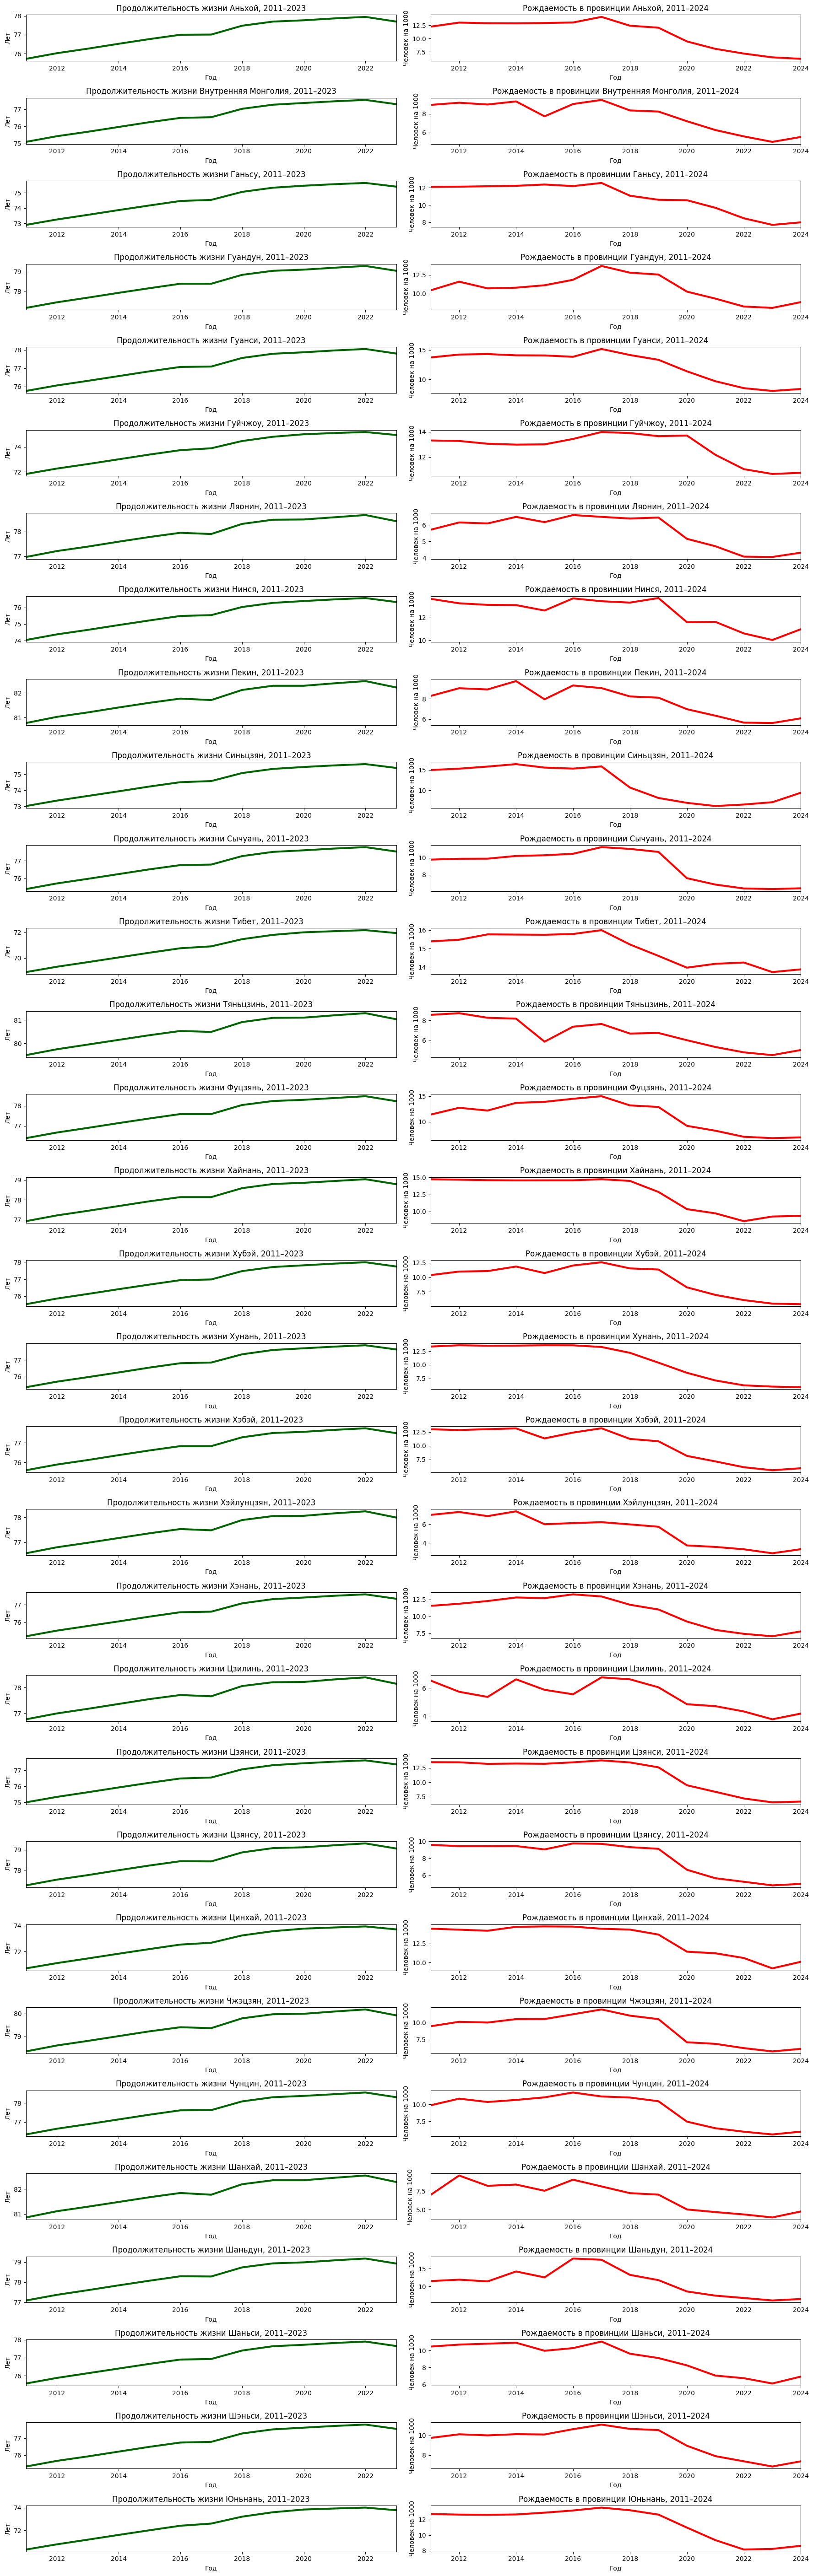

In [38]:
fig, ax = plt.subplots(31,2,figsize=(18, 60))
## Ожидаемая продолжительность жизни в Китае по провинциям 2011-2023

for i, region in enumerate(regions):
    province = df_life_clean[df_life_clean['Region'] == region].sort_values('Year')
    ax[i,0].plot(province['Year'],province['lifexp'],color='darkgreen',linewidth=3)
    
    ax[i,0].set_xlim(2011,2023)
    ax[i,0].set_xlabel('Год')
    ax[i,0].set_ylabel('Лет')
    ax[i,0].set_title(f'Продолжительность жизни {region}, 2011–2023')
    
## Рождаемость в Китае по провинциям 2011-2024

for i, region in enumerate(regions):
    province = df_fertility_reg[df_fertility_reg['name_region'] == region].sort_values('year')
    ax[i,1].plot(province['year'],province['birth_rate'],color='red',linewidth=3)
    
    ax[i,1].set_xlim(2011,2024)
    ax[i,1].set_xlabel('Год')
    ax[i,1].set_ylabel('Человек на 1000')
    ax[i,1].set_title(f'Рождаемость в провинции {region}, 2011–2024')
    

plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.subplots_adjust(hspace=0.8)
fig.savefig('../figures/life_expectancy_birth_rate.png', dpi=150, bbox_inches='tight')



### 6. Выводы

Исследование данных за 2011–2024 годы выявило значительные изменения экологических показателей Китая после начала государственных реформ 2013 года. Существенное сокращение выбросов диоксида серы, оксидов азота и твёрдых загрязняющих частиц происходило на фоне сохранения масштабной промышленной деятельности. Это позволяет говорить о результатах экологической модернизации и признаках разъединения динамики промышленного производства и экологической нагрузки.

Одновременно наблюдался устойчивый рост реальных располагаемых доходов городского и сельского населения. Во многих провинциях доходы, скорректированные на инфляцию, увеличились в два раза и более. На мой взгляд, сочетание масштабного сокращения загрязнения с ростом реальных доходов является одним из наиболее впечатляющих результатов преобразований Китая.

Однако улучшение экологических и экономических показателей не сопровождалось столь же однозначными изменениями в медицинской и демографической статистике. Заболеваемость астмой и раком гортани демонстрировала рост, а устойчивого снижения заболеваемости раком лёгких за исследуемый период не наблюдалось. Последствия многолетнего загрязнения, наряду с курением и другими факторами риска, могут проявляться значительно позже экологических преобразований.

Ожидаемая продолжительность жизни увеличилась практически во всех регионах Китая, тогда как рождаемость существенно снизилась. Это стало одним из наиболее интересных противоречий исследования: повышение текущего благополучия населения не обязательно сопровождается улучшением условий для рождения и воспитания следующего поколения.

**Основной вывод:** десяти лет оказалось достаточно, чтобы увидеть масштабные результаты экологической модернизации Китая, однако улучшение промышленных и экономических показателей не означает одновременного решения всех медицинских и демографических проблем. Обнаруженные тенденции показывают результаты преобразований, но не доказывают прямых причинных связей между всеми рассмотренными показателями.